### All needed modules

In [68]:
import torch
import torch.nn as nn
import torchvision
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import time
import os

from torch.utils.data import DataLoader, random_split

## Equation

### $$y = H(x, W_H) \cdot T(x, W_T) + x \cdot \left(1 - T(x, W_T)\right)$$




#### choosing device

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


#### Basic parameters

In [70]:
DEPTH = 50
WIDTH = 50
EPOCHS = 100
BATCH_SIZE = 128
LEARNING_RATE = 0.05

os.makedirs("results", exist_ok=True)
os.makedirs("results/depth_10x50", exist_ok=True)

## Highway network

In [71]:
class HighwayLayer(nn.Module):
    def __init__(self, size, gate_bias=-4.0):
        super().__init__()

        self.H = nn.Linear(size, size)
        self.T = nn.Linear(size, size)

        self.activation = nn.ReLU()

        nn.init.kaiming_normal_(self.H.weight, nonlinearity="relu")
        nn.init.zeros_(self.H.bias)

        nn.init.kaiming_normal_(self.T.weight, nonlinearity="linear")
        nn.init.zeros_(self.T.bias)
        nn.init.constant_(self.T.bias, gate_bias)

    def forward(self, x):
        h = self.activation(self.H(x))
        t = torch.sigmoid(self.T(x))

        return h * t + x * (1 - t)

In [73]:
class HighwayNet(nn.Module):
    def __init__(self, input_size=3072, depth=50, width=50, num_classes=10):
        super().__init__()

        self.input_layer = nn.Linear(input_size, width)
        self.activation = nn.ReLU()

        nn.init.kaiming_normal_(self.input_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.input_layer.bias)

        self.highway_layers = nn.ModuleList([HighwayLayer(width) for _ in range(depth - 1)])

        self.output_layer = nn.Linear(width, num_classes)

        nn.init.xavier_normal_(self.output_layer.weight)
        nn.init.zeros_(self.output_layer.bias)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.activation(self.input_layer(x))

        for layer in self.highway_layers:
            x = layer(x)

        return self.output_layer(x)

In [74]:
model = HighwayNet(depth=DEPTH, width=WIDTH).to(device)
print(model)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

HighwayNet(
  (input_layer): Linear(in_features=3072, out_features=50, bias=True)
  (activation): ReLU()
  (highway_layers): ModuleList(
    (0-48): 49 x HighwayLayer(
      (H): Linear(in_features=50, out_features=50, bias=True)
      (T): Linear(in_features=50, out_features=50, bias=True)
      (activation): ReLU()
    )
  )
  (output_layer): Linear(in_features=50, out_features=10, bias=True)
)
Number of parameters: 404060


#### Downloading CIFAR10

In [75]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

Training images: 50000
Test images: 10000


In [76]:
train_dataset, val_dataset = random_split(
    train_data,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

classes = train_dataset.dataset.classes

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_data))

Train: 45000
Validation: 5000
Test: 10000


## Training

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.99)

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_acc = 0.0

for epoch in range(EPOCHS):

    start_time = time.time()

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_acc = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(model.state_dict(), "results/depth_50x50/best_model.pth")

    scheduler.step()

    epoch_time = time.time() - start_time

    print(f"Epoch [{epoch+1}/{EPOCHS}] " f"Train Loss: {train_loss:.4f} " f"Train Acc: {train_acc:.4f} " f"Val Loss: {val_loss:.4f} " f"Val Acc: {val_acc:.4f} " f"Time: {epoch_time:.1f}s" )

np.savez("results/training_history.npz", train_losses=train_losses, val_losses=val_losses, train_accuracies=train_accuracies, val_accuracies=val_accuracies)

print("\nTraining completed!")
print("Best validation accuracy:", best_val_acc)

Epoch [1/100] Train Loss: 1.8078 Train Acc: 0.3687 Val Loss: 1.6939 Val Acc: 0.3964 Time: 6.2s
Epoch [2/100] Train Loss: 1.6022 Train Acc: 0.4298 Val Loss: 1.5899 Val Acc: 0.4384 Time: 6.4s
Epoch [3/100] Train Loss: 1.5218 Train Acc: 0.4573 Val Loss: 1.5584 Val Acc: 0.4566 Time: 6.7s
Epoch [4/100] Train Loss: 1.4667 Train Acc: 0.4760 Val Loss: 1.5551 Val Acc: 0.4522 Time: 7.2s
Epoch [5/100] Train Loss: 1.4139 Train Acc: 0.4971 Val Loss: 1.5220 Val Acc: 0.4658 Time: 5.0s
Epoch [6/100] Train Loss: 1.3792 Train Acc: 0.5074 Val Loss: 1.5171 Val Acc: 0.4724 Time: 7.1s
Epoch [7/100] Train Loss: 1.3370 Train Acc: 0.5236 Val Loss: 1.5119 Val Acc: 0.4614 Time: 6.7s
Epoch [8/100] Train Loss: 1.3002 Train Acc: 0.5368 Val Loss: 1.5677 Val Acc: 0.4630 Time: 6.3s
Epoch [9/100] Train Loss: 1.2721 Train Acc: 0.5460 Val Loss: 1.5232 Val Acc: 0.4758 Time: 6.3s
Epoch [10/100] Train Loss: 1.2413 Train Acc: 0.5553 Val Loss: 1.5627 Val Acc: 0.4650 Time: 6.9s
Epoch [11/100] Train Loss: 1.2107 Train Acc: 0.56

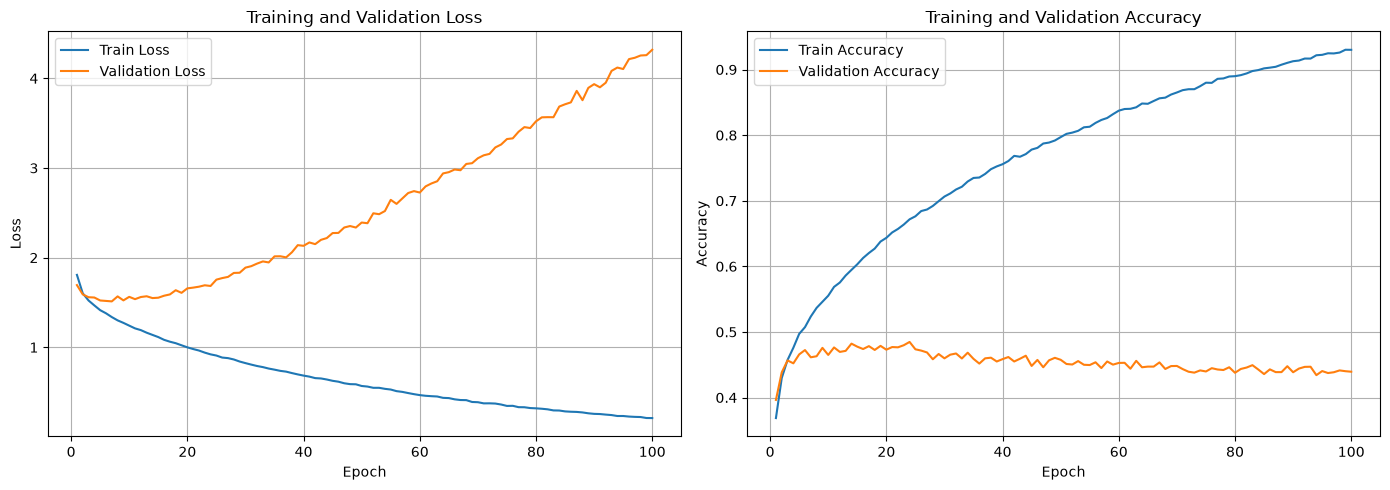

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig("results/training_curves.png", dpi=300)

plt.show()

In [ ]:
model.load_state_dict(torch.load("results/depth_10x50/best_model.pth", map_location=device))

model.eval()

correct = 0
total = 0
test_loss = 0.0

all_images = []
all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if len(all_images) == 0:
            all_images = images[:16].cpu()
            all_labels = labels[:16].cpu()
            all_predictions = predictions[:16].cpu()

test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 1.7032
Test Accuracy: 47.41%


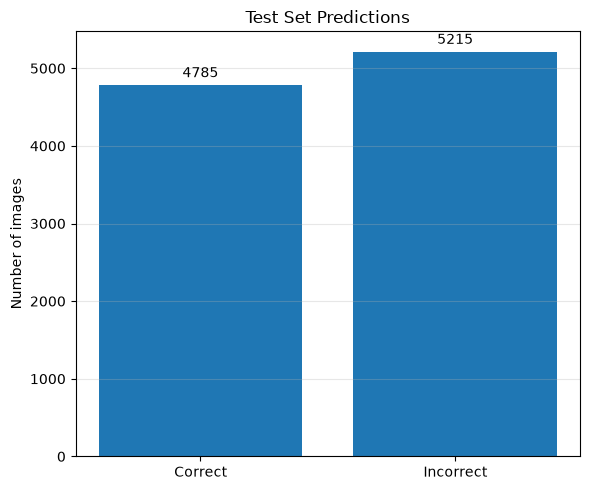

Correct predictions: 4785 (47.85%)
Incorrect predictions: 5215 (52.15%)


In [ ]:
incorrect = total - correct

plt.figure(figsize=(6, 5))

plt.bar(["Correct", "Incorrect"], [correct, incorrect])

plt.ylabel("Number of images")
plt.title("Test Set Predictions")

for i, value in enumerate([correct, incorrect]):
    plt.text(i, value + 100, str(value), ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("results/test_predictions_summary.png", dpi=150)
plt.show()

print(f"Correct predictions: {correct} ({correct / total * 100:.2f}%)")
print(f"Incorrect predictions: {incorrect} ({incorrect / total * 100:.2f}%)")

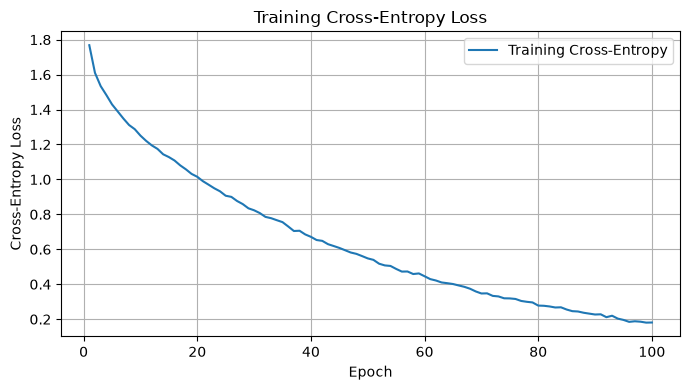

In [53]:
plt.figure(figsize=(7, 4))

plt.plot(epochs, train_losses, label="Training Cross-Entropy")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Cross-Entropy Loss")

plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig("results/training_cross_entropy.png", dpi=150)
plt.show()

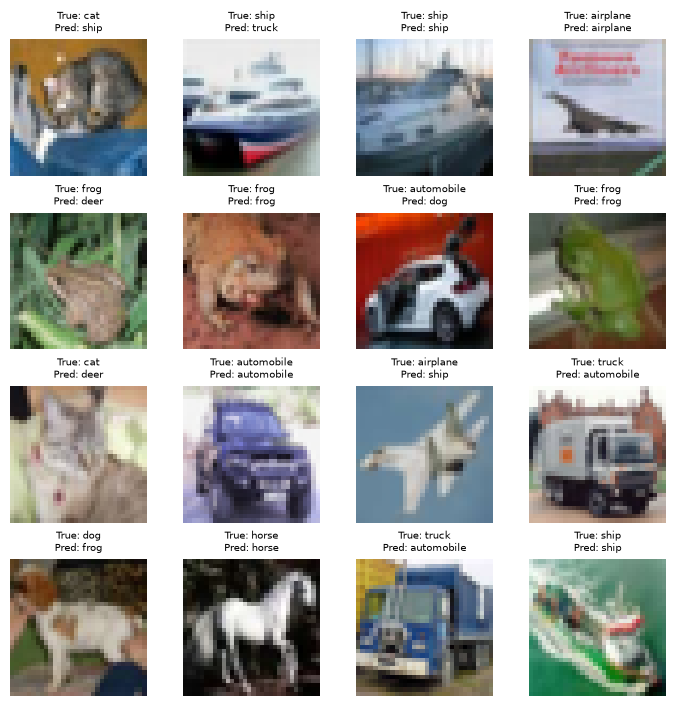

In [ ]:
mean = torch.tensor((0.4914, 0.4822, 0.4465)).view(3, 1, 1)
std = torch.tensor((0.2470, 0.2435, 0.2616)).view(3, 1, 1)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):

    image = all_images[i] * std + mean
    image = image.clamp(0, 1)

    true_label = classes[all_labels[i]]
    predicted_label = classes[all_predictions[i]]

    ax.imshow(image.permute(1, 2, 0))

    ax.set_title(f"True: {true_label}\nPred: {predicted_label}", fontsize=7)

    ax.axis("off")

plt.tight_layout(pad=0.5)
plt.savefig("results/predictions.png", dpi=100)
plt.show()

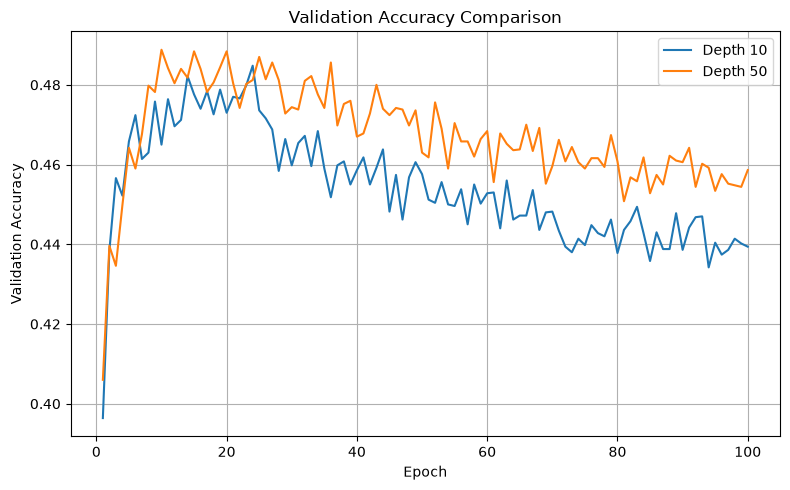

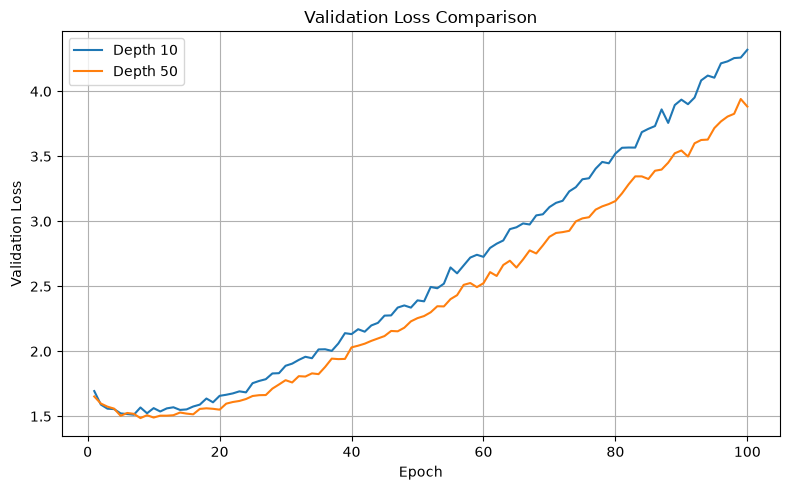

In [ ]:

data_50 = np.load("results/depth_50x50/training_history.npz")
data_10 = np.load("results/depth_10x50/training_history.npz")

epochs = range(1, 101)

plt.figure(figsize=(8, 5))

plt.plot(epochs, data_10["val_accuracies"], label="Depth 10")
plt.plot(epochs, data_50["val_accuracies"], label="Depth 50")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("results/depth_comparison_accuracy.png", dpi=150)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs, data_10["val_losses"], label="Depth 10")
plt.plot(epochs, data_50["val_losses"], label="Depth 50")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("results/depth_comparison_loss.png", dpi=150)
plt.show()